# Retail Customer Segmentation

**Algorithms Compared:** K-Means Clustering, Hierarchical Agglomerative Clustering (Ward Linkage), and DBSCAN  
**Dataset:** UCI Machine Learning Repository — *Online Retail* (`data/Online Retail.xlsx`)

## 1. Problem Statement
Online retailers serve diverse shoppers—from one-time seasonal buyers to wholesale resellers—yet often send uniform promotions. We group customers by **recency**, **purchase frequency**, **spending**, and **product preferences** so marketing and merchandising teams can tailor outreach, retain high-value buyers, and improve relevance without blanket discounting.

## 2. Dataset & Limitations
* **Source:** UCI Online Retail Dataset (541,909 raw line items, Dec 2010–Dec 2011).
* **Cleaning:** Removes missing `CustomerID` (135,080 rows), duplicates (5,225), cancellations (`C` prefix), non-positive quantities/prices, and non-product fees (`POST`, `DOT`, `M`, etc.), leaving **391,283** clean purchases across **4,334** customers.
* **Limitations:** ~25% unattributed guest rows, >90% UK concentration, wholesale outliers, and a single-year horizon.

In [1]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_and_cache_data
from src.preprocessing import MODEL_FEATURES, split_data, fit_transform_splits
from src.train_evaluate import run_training_and_evaluation, predict_new_customer

clean_df, features_df, audit = load_and_cache_data(PROJECT_ROOT, force_rebuild=False)
print(f"Clean transactions: {len(clean_df):,} | Unique customers: {len(features_df):,}")
display(features_df[MODEL_FEATURES + ["AvgOrderValue", "CategoryEntropy"]].describe().T[["count", "mean", "50%", "min", "max"]].round(2))

Clean transactions: 391,283 | Unique customers: 4,334


,count,mean,50%,min,max
RecencyDays,4334.0,92.70,51.00,1.00,374.00
Frequency,4334.0,4.25,2.00,1.00,206.00
Monetary,4334.0,2017.52,663.71,3.75,279138.02
UniqueProducts,4334.0,61.43,35.00,1.00,1786.00
AvgOrderValue,4334.0,415.67,289.77,3.75,84236.25
CategoryEntropy,4334.0,0.69,0.77,-0.00,1.00


## 3. Leak-Free 60% / 20% / 20% Train / Validation / Test Pipeline
Customer IDs (`CustomerID`) and geographic attributes (`PrimaryCountry`, `IsUK`) are removed from clustering inputs and kept strictly for auditing. `log1p` and `StandardScaler` are fitted only on the **60% Training set (2,600 customers)**, tuned on the **20% Validation set (867 customers)**, and evaluated on the **20% Held-Out Test set (867 customers)**.

In [2]:
train_df, val_df, test_df = split_data(features_df, random_state=42)
print(f"Split sizes -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

results = run_training_and_evaluation(features_df, PROJECT_ROOT, selected_k=4)
print("\n=== 60/20/20 Algorithm Comparison ===")
display(results["comparison_df"])

Split sizes -> Train: 2600, Val: 867, Test: 867



=== 60/20/20 Algorithm Comparison ===


,algorithm,train_clusters,train_noise_pct,train_silhouette,val_silhouette,test_silhouette,test_davies_bouldin,test_calinski_harabasz,test_noise_pct
0,K-Means (k=4),4,0.00,0.2867,0.2898,0.2724,1.2206,507.50,0.00
1,Hierarchical Ward (k=4),4,0.00,0.2151,0.2381,0.2376,1.2926,509.44,0.00
2,"DBSCAN (eps=0.55, min_samples=8)",3,9.62,0.2271,0.2020,0.1838,0.9861,236.40,6.69


## 4. Diagnostic Charts, Segment Profiles & Error Analysis

,SegmentPersona,Customers,SharePct,MedianRecency,MedianFrequency,MedianMonetary,TotalRevenue,RevenueSharePct,MedianUniqueProducts,MeanCategoryEntropy,UKSharePct
0,At-Risk / Hibernating,1506,34.75,172.0,1.0,246.71,453909.89,5.19,13.0,0.55,91.63
1,Champions (VIP),811,18.71,10.0,9.0,3408.20,5931793.90,67.84,121.0,0.81,89.27
2,Loyal Regulars,1184,27.32,71.0,3.0,1094.14,1785286.99,20.42,58.0,0.78,88.77
3,Recent Emerging,833,19.22,16.0,2.0,550.06,572922.86,6.55,31.0,0.71,91.36



Error & Fairness Audit:
  total_customers: 4334
  split_sizes: {'train_60': 2600, 'val_20': 867, 'test_20': 867}
  negative_silhouette_count: 105
  negative_silhouette_pct: 2.42
  boundary_customer_medians: {'RecencyDays': 29.0, 'Frequency': 4.0, 'Monetary': 1389.41, 'UniqueProducts': 62.0}
  core_customer_medians: {'RecencyDays': 52.0, 'Frequency': 2.0, 'Monetary': 650.41, 'UniqueProducts': 35.0}
  dbscan_noise_count: 281
  dbscan_noise_pct: 6.48
  dbscan_noise_medians: {'RecencyDays': 16.0, 'Frequency': 5.0, 'Monetary': 3041.64, 'UniqueProducts': 19.0}
  bootstrap_ari_mean: 0.8582
  bootstrap_ari_std: 0.1703
  bootstrap_ari_scores: [0.9289, 0.9299, 0.8247, 0.9781, 0.9345, 0.8372, 0.3666, 0.9655, 0.9057, 0.9109]
  fairness_audit: {'uk_overall_pct': 90.36, 'uk_boundary_error_pct': 2.43, 'non_uk_boundary_error_pct': 2.39, 'uk_vip_rate_pct': 18.49, 'non_uk_vip_rate_pct': 20.81}


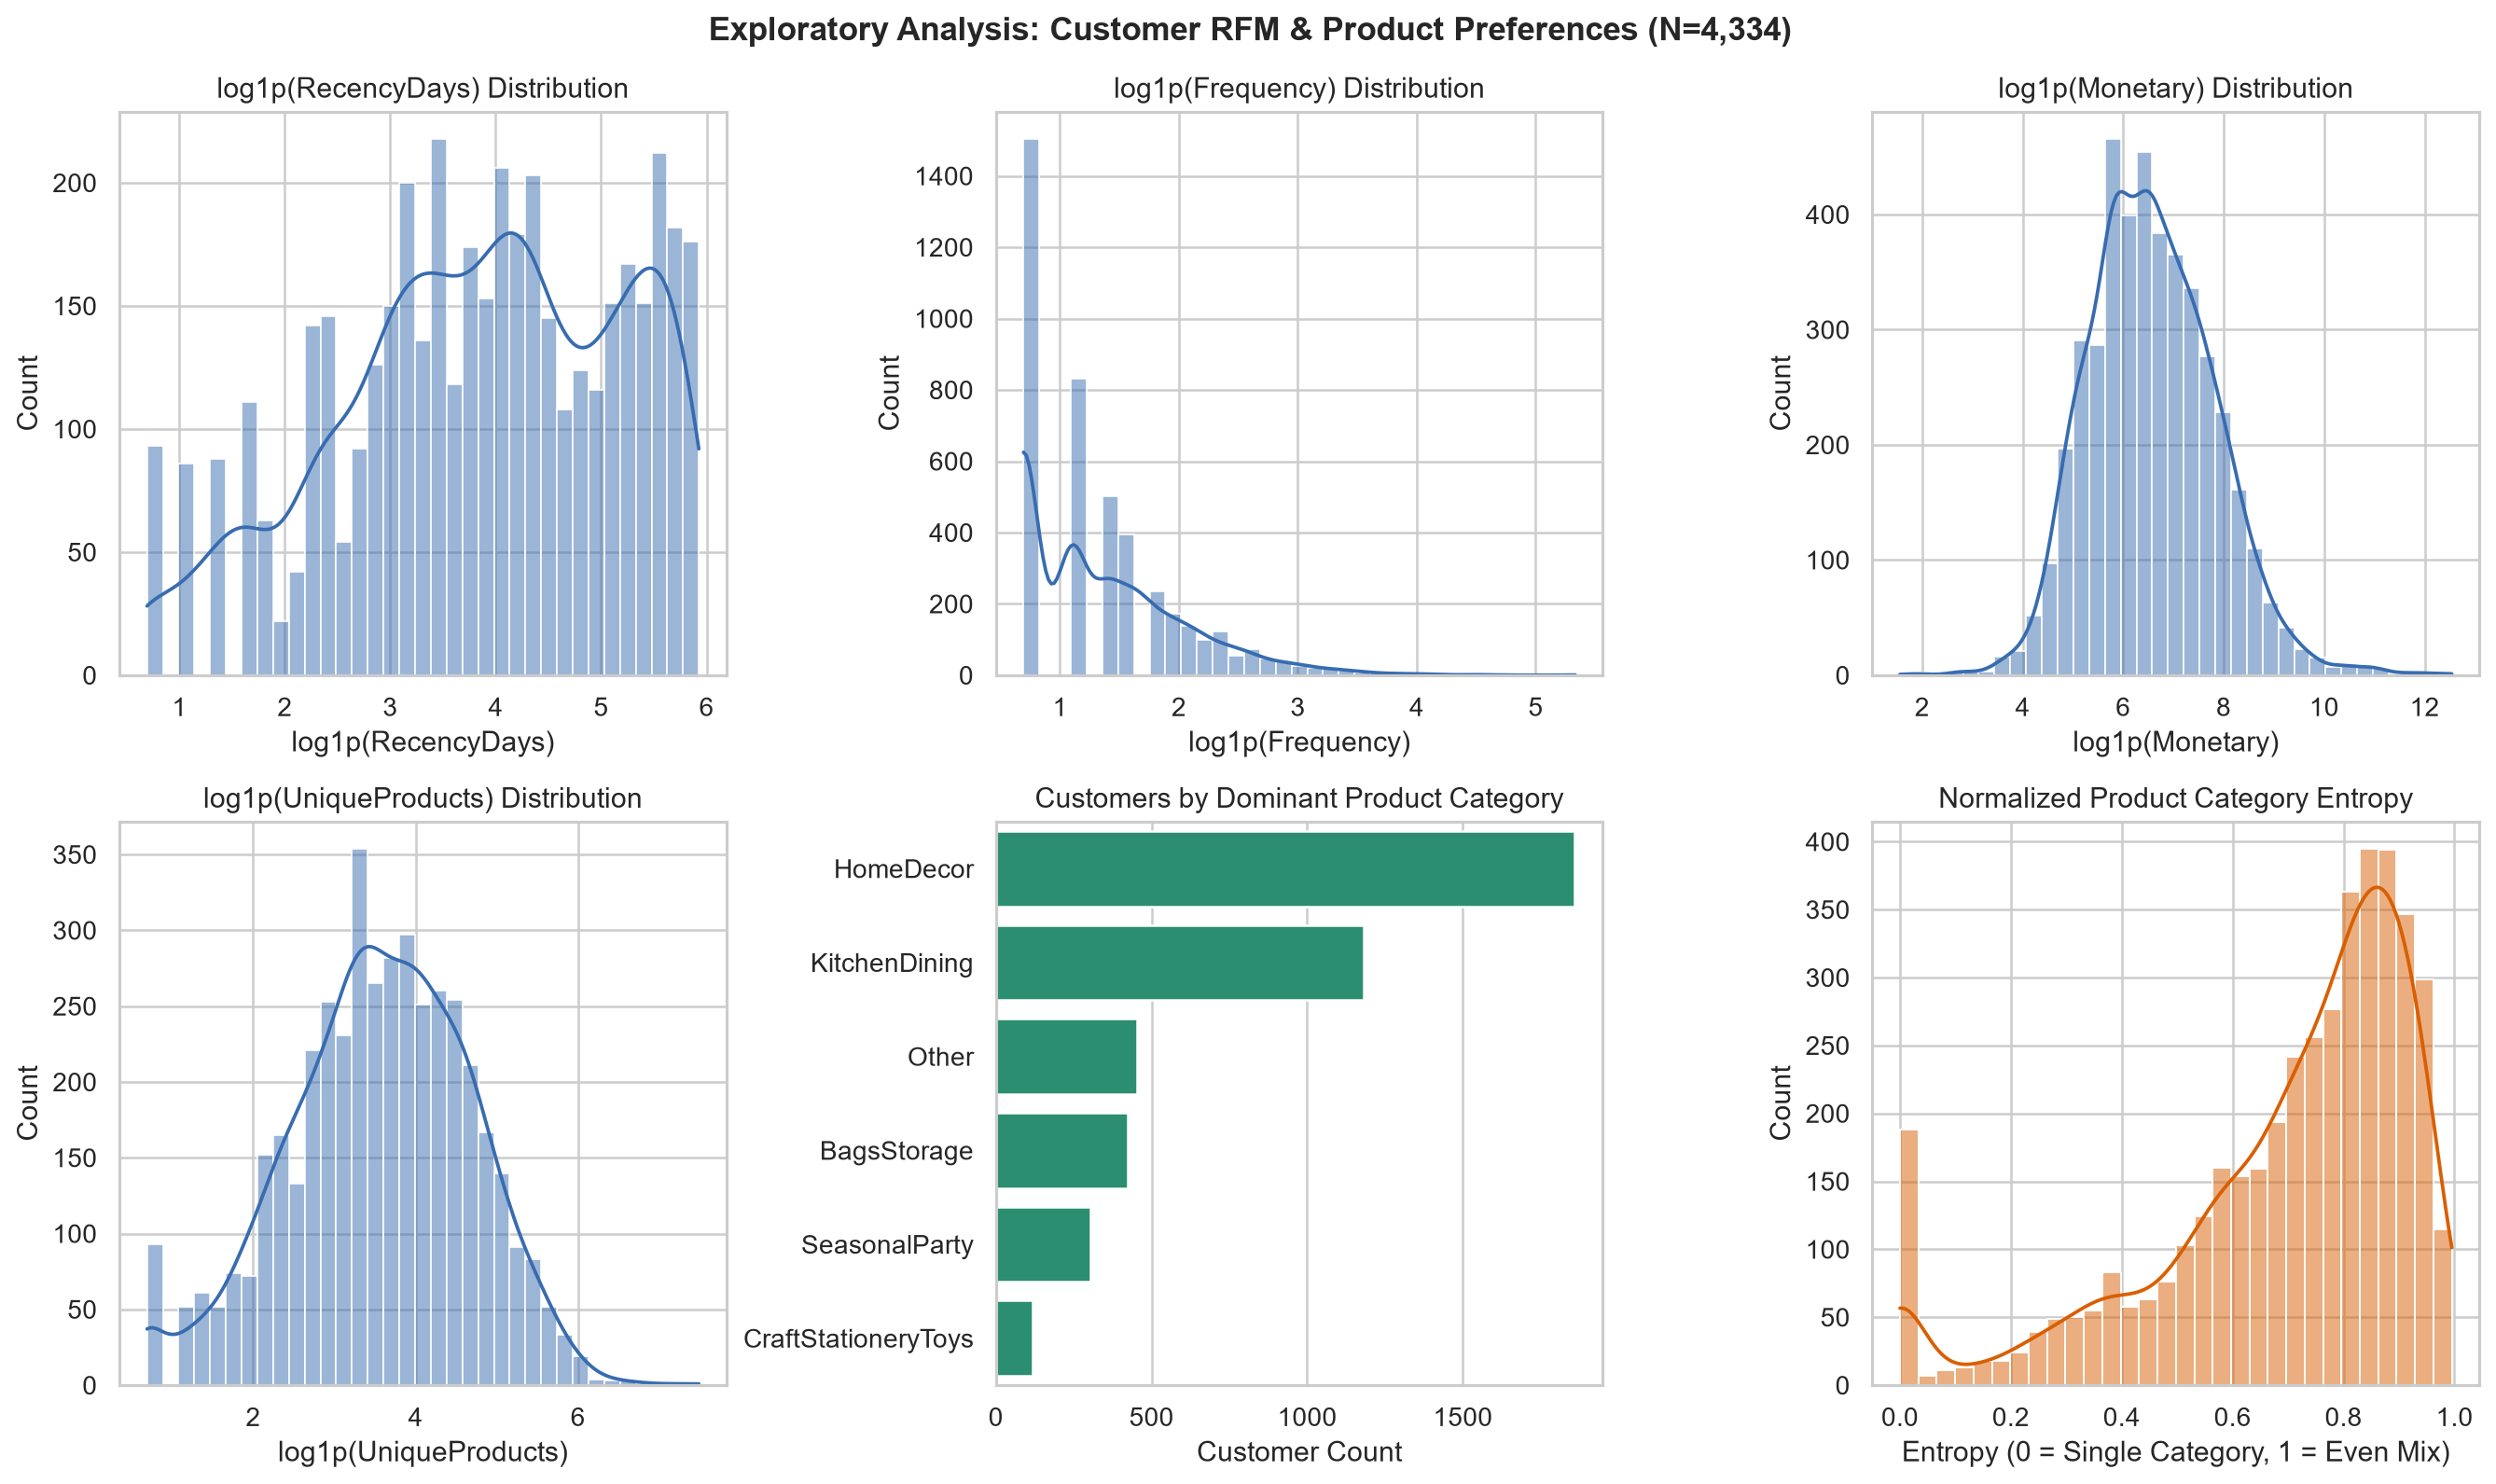

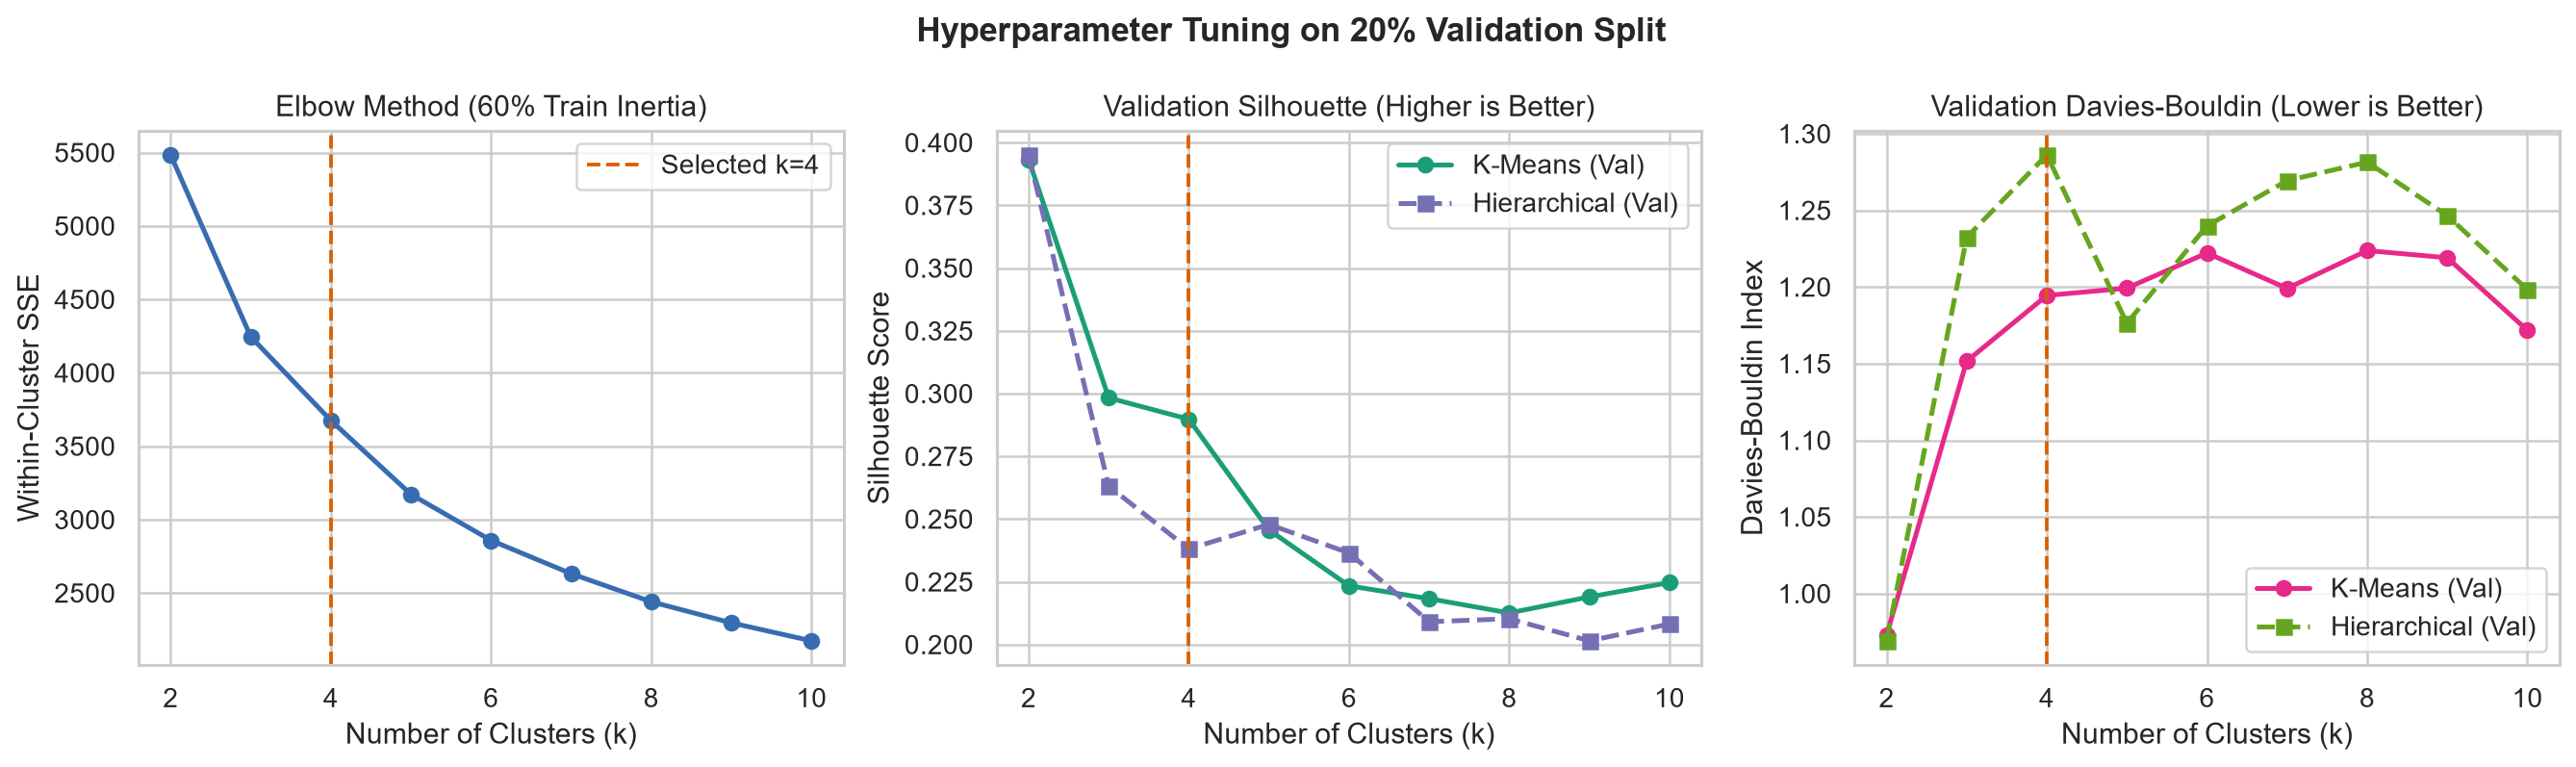

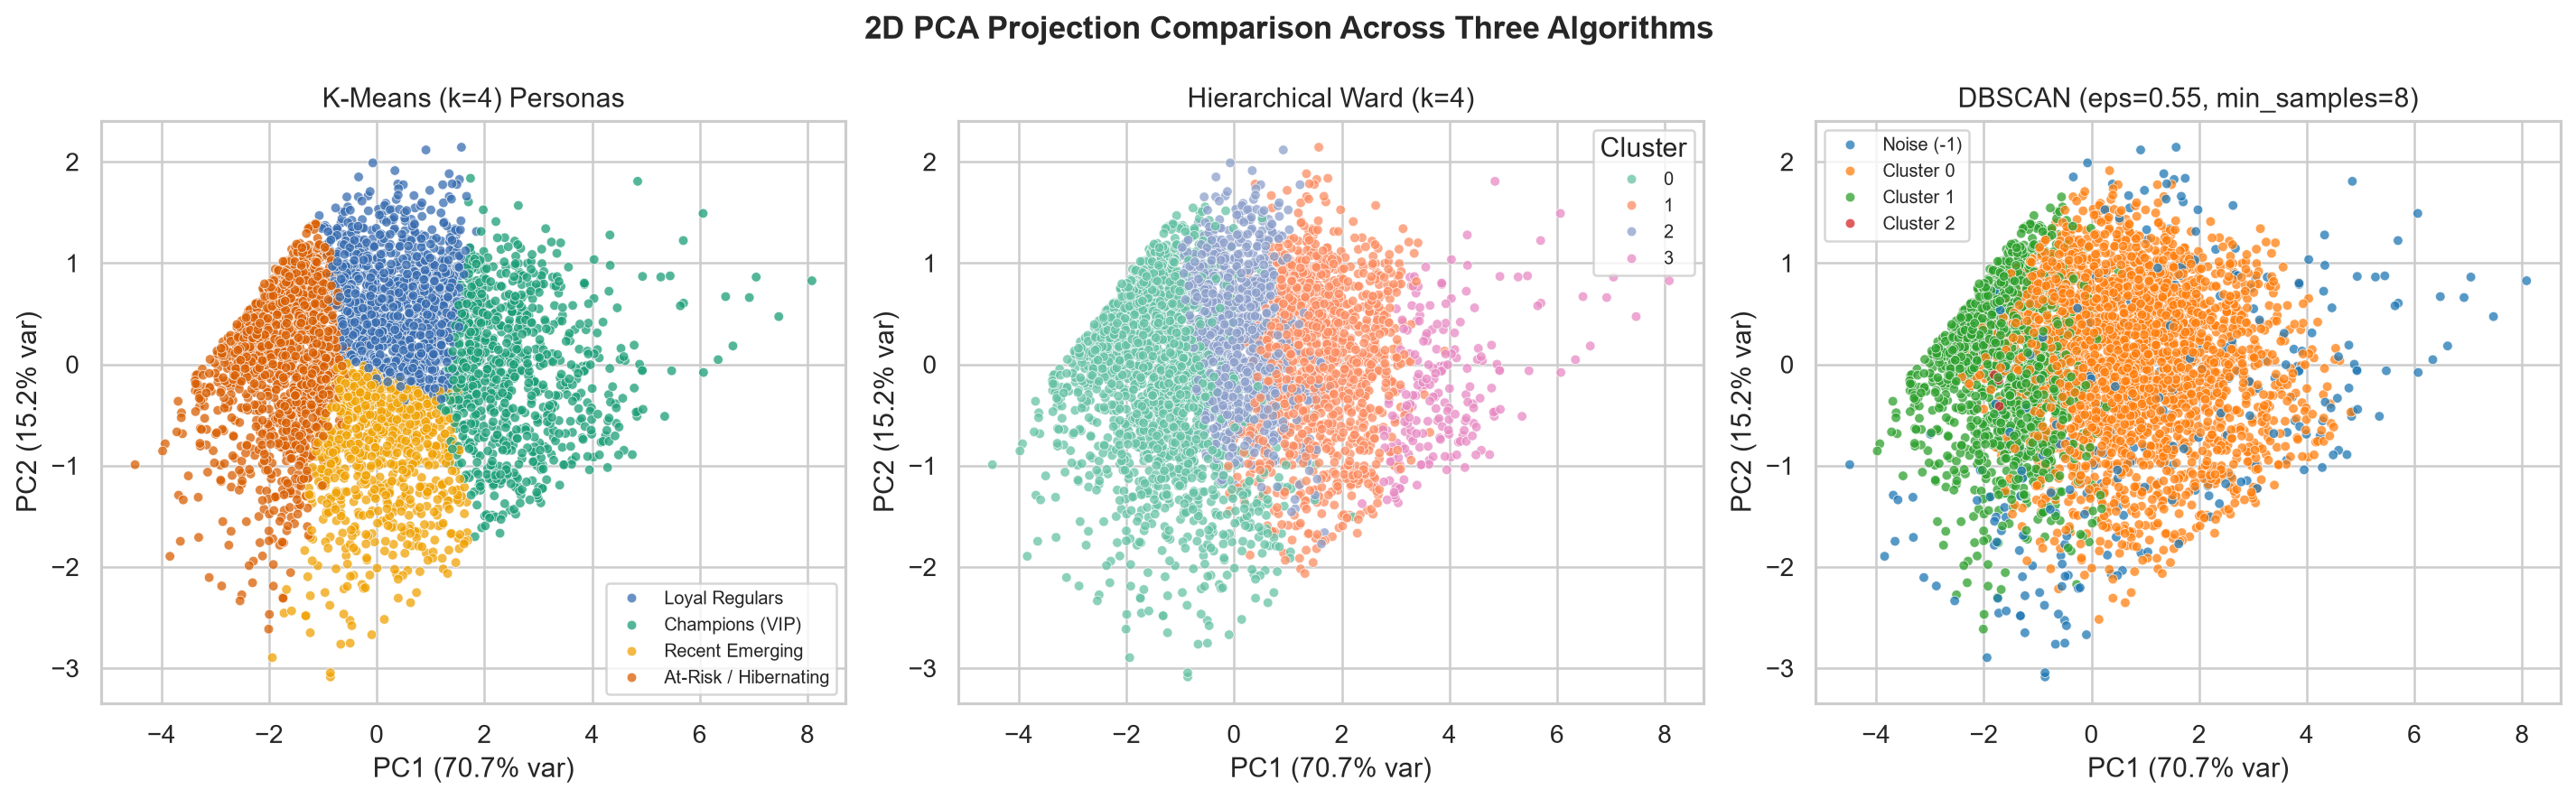

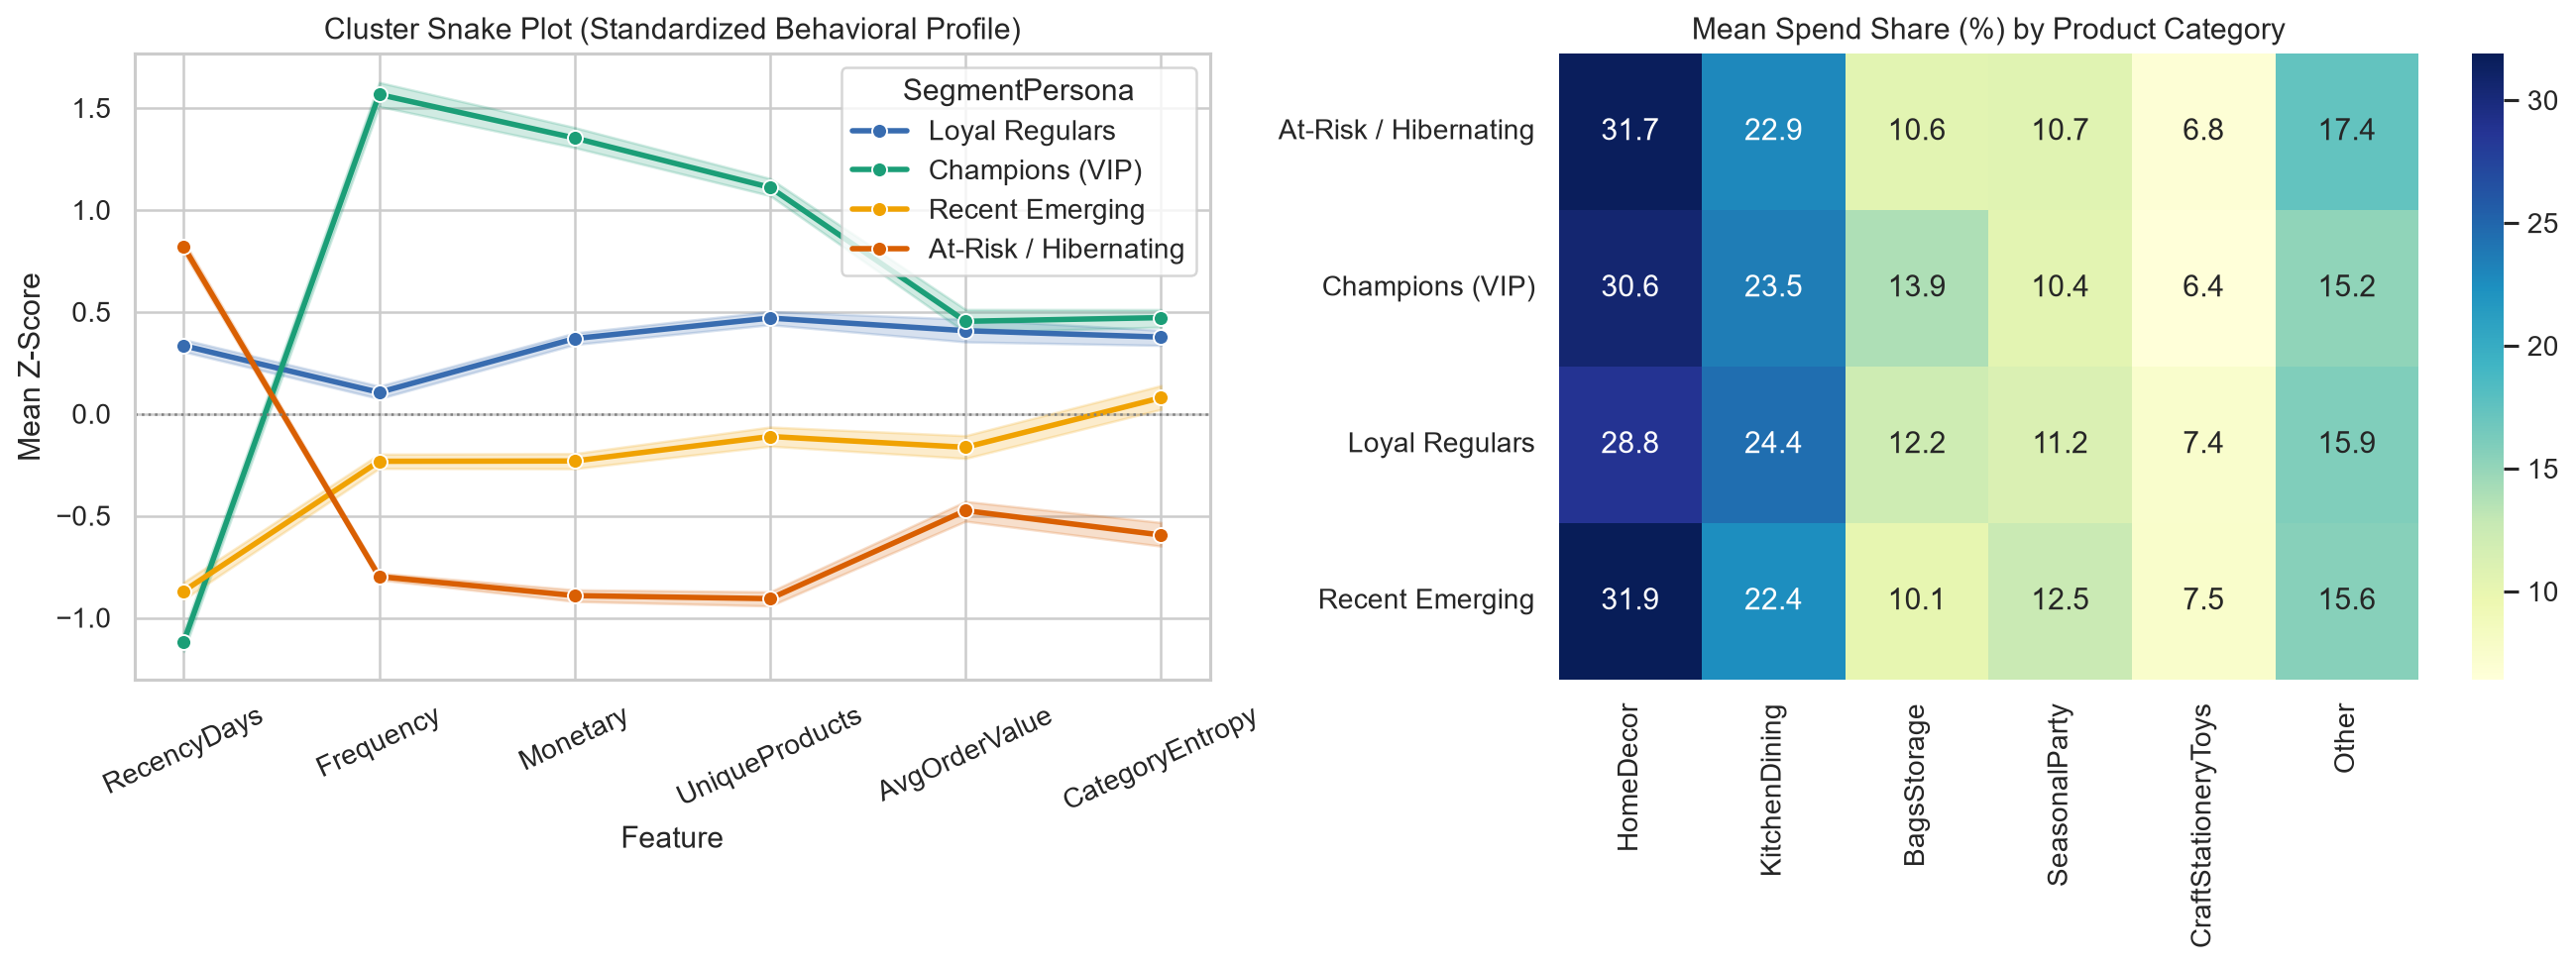

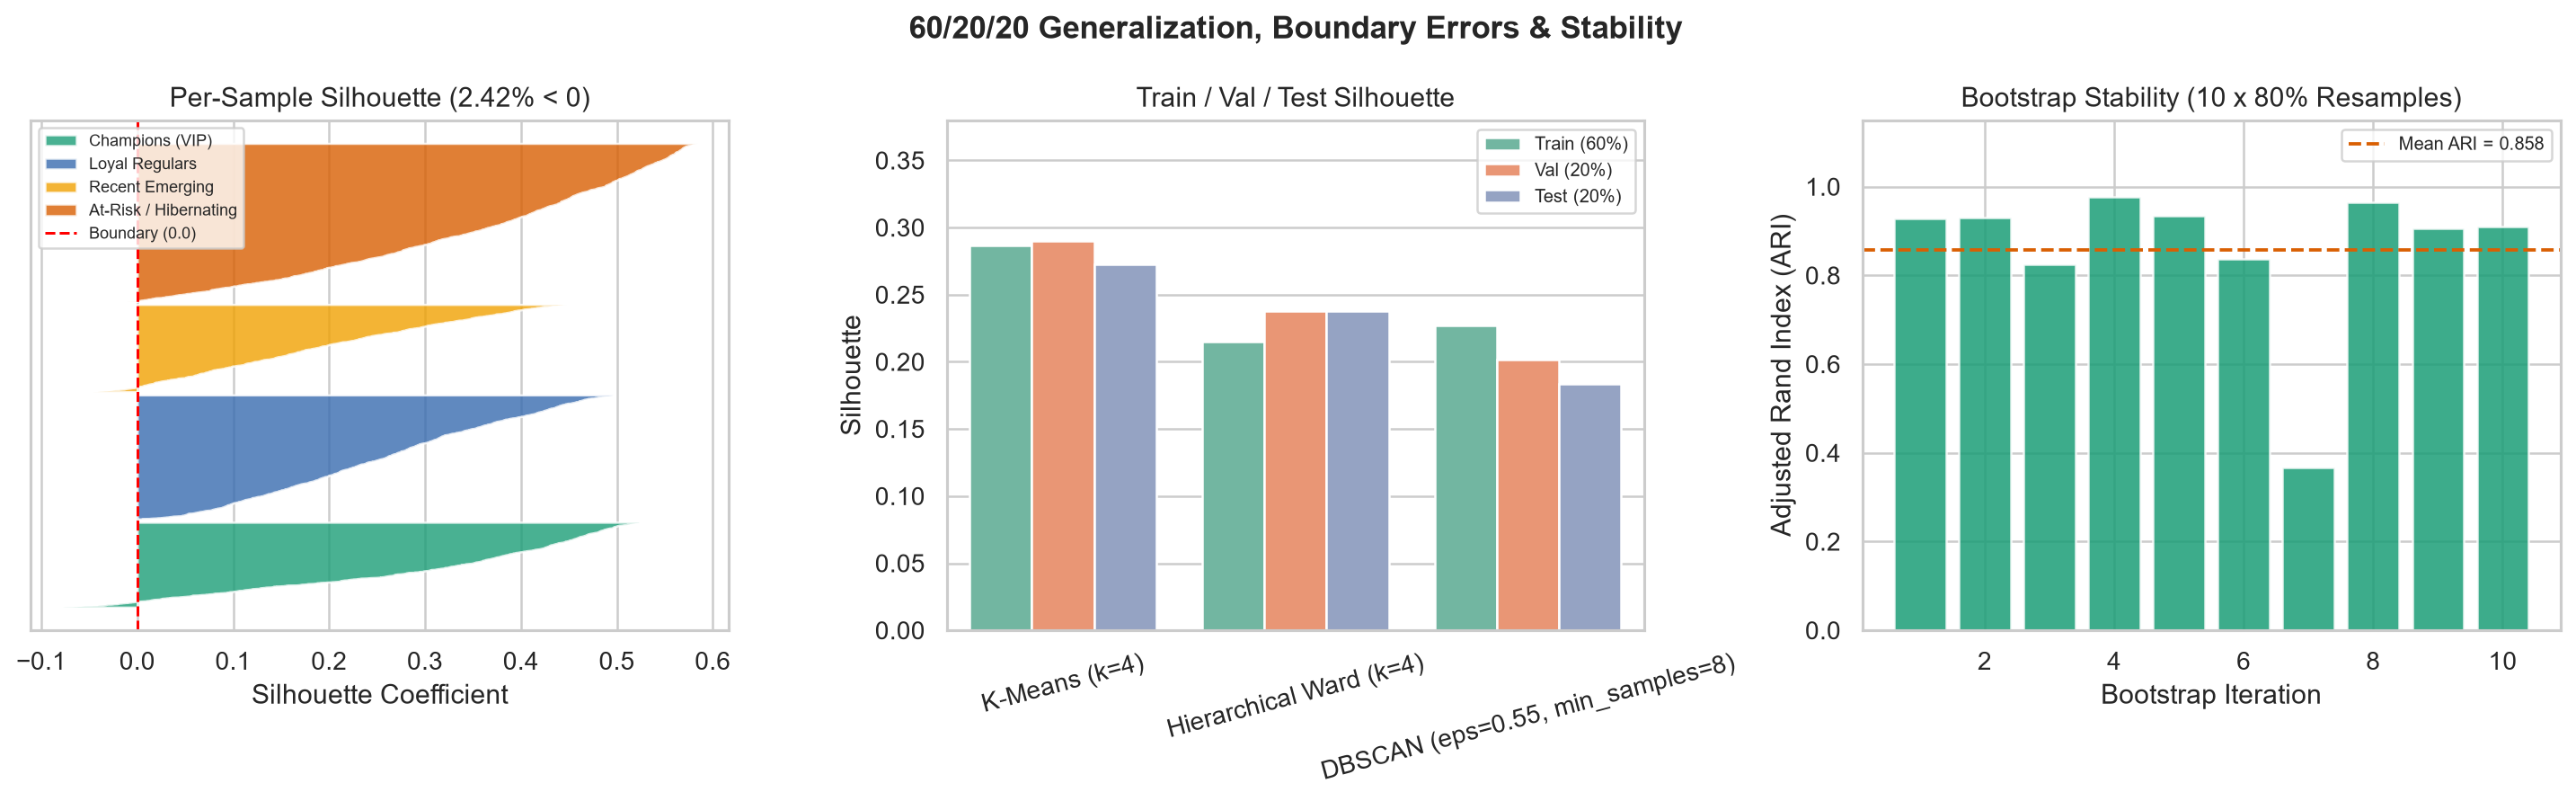

In [3]:
display(results["profile_table"])
print("\nError & Fairness Audit:")
for k, v in results["error_analysis"].items():
    print(f"  {k}: {v}")

for fname in [
    "01_eda_distributions.png",
    "02_validation_tuning.png",
    "05_model_comparison_pca.png",
    "06_segment_profiles.png",
    "07_error_stability_analysis.png",
]:
    display(Image(filename=str(PROJECT_ROOT / "artifacts" / "plots" / fname)))

## 5. Interactive Decision-Support Inference Demo

In [4]:
bundle = results["pipeline_bundle"]
for name, params in [
    ("Boutique VIP", dict(recency_days=7, frequency=14, monetary=4850.0, unique_products=145, dominant_category="HomeDecor")),
    ("Repeat Kitchen Enthusiast", dict(recency_days=38, frequency=4, monetary=920.0, unique_products=42, dominant_category="KitchenDining")),
    ("First-Time Seasonal Buyer", dict(recency_days=15, frequency=1, monetary=165.0, unique_products=12, dominant_category="SeasonalParty")),
    ("Lapsed Buyer", dict(recency_days=220, frequency=1, monetary=110.0, unique_products=8, dominant_category="BagsStorage")),
]:
    pred = predict_new_customer(bundle, **params)
    print(f"{name}: {pred['segment_persona']} ({pred['confidence_pct']}% confidence) -> {pred['recommended_strategy']}")

Boutique VIP: Champions (VIP) (68.6% confidence) -> Invite to VIP loyalty tier, offer early access to new arrivals, and provide bundle perks instead of heavy discounting.
Repeat Kitchen Enthusiast: Loyal Regulars (46.0% confidence) -> Send cross-category recommendations (e.g., matching KitchenDining & HomeDecor items) and free-shipping basket incentives.
First-Time Seasonal Buyer: Recent Emerging (36.2% confidence) -> Run 30-day second-order follow-ups highlighting their top product category and starter bundles.
Lapsed Buyer: At-Risk / Hibernating (58.7% confidence) -> Trigger targeted digital win-back offers on bestsellers in their historical category preference.
